In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import sklearn

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer 

In [2]:
df = pd.read_csv("C:\\Users\\Navneet tiwari\\CAR SALES DATA\\CAR SALES DATA\\car_prices.csv")


In [3]:
df.head()

,year,make,model,trim,body,transmission,state,condition,odometer,color,interior,seller,mmr,sellingprice
0,2015,Kia,Sorento,LX,SUV,automatic,ca,5.0,16639.0,white,black,kia motors america inc,20500.0,21500.0
1,2015,Kia,Sorento,LX,SUV,automatic,ca,5.0,9393.0,white,beige,kia motors america inc,20800.0,21500.0
2,2014,BMW,3 Series,328i SULEV,Sedan,automatic,ca,45.0,1331.0,gray,black,financial services remarketing (lease),31900.0,30000.0
3,2015,Volvo,S60,T5,Sedan,automatic,ca,41.0,14282.0,white,black,volvo na rep/world omni,27500.0,27750.0
4,2014,BMW,6 Series Gran Coupe,650i,Sedan,automatic,ca,43.0,2641.0,gray,black,financial services remarketing (lease),66000.0,67000.0


In [4]:
df.columns

Index(['year', 'make', 'model', 'trim', 'body', 'transmission', 'state',
       'condition', 'odometer', 'color', 'interior', 'seller', 'mmr',
       'sellingprice'],
      dtype='str')

In [5]:
df.shape ## rows and columns

(558837, 14)

In [6]:
df_clean = df.dropna()

print("Total complete records:", df_clean.shape[0])

Total complete records: 472325


In [7]:
total = df.shape[0]
complete = df.dropna().shape[0]

print("Total records:", total)
print(" Records without missing values:", complete)
print("Complete data percentage:", (complete / total) * 100)

Total records: 558837
 Records without missing values: 472325
Complete data percentage: 84.51927843002521


In [8]:
df.isnull().sum().sort_values(ascending=False)


transmission    65352
body            13195
condition       11820
trim            10651
model           10399
make            10301
interior          749
color             749
odometer           94
mmr                38
sellingprice       12
year                0
state               0
seller              0
dtype: int64

In [9]:
total = len(df)

present = df.notnull().sum()
missing = df.isnull().sum()
present_percentage = (present / total) * 100

result = pd.DataFrame({
    "Present Data": present,
    "Missing Values": missing,
    "Present Percentage": present_percentage
})

print(result)

              Present Data  Missing Values  Present Percentage
year                558837               0          100.000000
make                548536           10301           98.156708
model               548438           10399           98.139171
trim                548186           10651           98.094078
body                545642           13195           97.638846
transmission        493485           65352           88.305713
state               558837               0          100.000000
condition           547017           11820           97.884893
odometer            558743              94           99.983179
color               558088             749           99.865972
interior            558088             749           99.865972
seller              558837               0          100.000000
mmr                 558799              38           99.993200
sellingprice        558825              12           99.997853


In [10]:
df["transmission"] = df["transmission"].fillna(df["transmission"].mode()[0])
df["body"] = df["body"].fillna(df["body"].mode()[0])
df["make"] = df["make"].fillna(df["make"].mode()[0])
df["model"] = df["model"].fillna(df["model"].mode()[0])
df["trim"] = df["trim"].fillna(df["trim"].mode()[0])
df["color"] = df["color"].fillna(df["color"].mode()[0])
df["interior"] = df["interior"].fillna(df["interior"].mode()[0])

In [11]:
df.isnull().sum()

year                0
make                0
model               0
trim                0
body                0
transmission        0
state               0
condition       11820
odometer           94
color               0
interior            0
seller              0
mmr                38
sellingprice       12
dtype: int64

In [12]:
from sklearn.impute import KNNImputer

imputer = KNNImputer(n_neighbors=5)

columns_to_impute = ['sellingprice', 'mmr', 'odometer', 'condition']

df[columns_to_impute] = imputer.fit_transform(df[columns_to_impute])

df.isnull().sum().sort_values(ascending=False)

year            0
make            0
model           0
trim            0
body            0
transmission    0
state           0
condition       0
odometer        0
color           0
interior        0
seller          0
mmr             0
sellingprice    0
dtype: int64

In [13]:
total = df.shape[0]
complete = df.dropna().shape[0]

print("Total records:", total)
print(" Records without missing values:", complete)
print("Complete data percentage  after filling missing values:", (complete / total) * 100)

Total records: 558837
 Records without missing values: 558837
Complete data percentage  after filling missing values: 100.0


In [14]:
total = len(df)

present = df.notnull().sum()
missing = df.isnull().sum()
present_percentage = (present / total) * 100

result = pd.DataFrame({
    "Present Data": present,
    "Missing Values": missing,
    "Present Percentage": present_percentage
})

print(result)

              Present Data  Missing Values  Present Percentage
year                558837               0               100.0
make                558837               0               100.0
model               558837               0               100.0
trim                558837               0               100.0
body                558837               0               100.0
transmission        558837               0               100.0
state               558837               0               100.0
condition           558837               0               100.0
odometer            558837               0               100.0
color               558837               0               100.0
interior            558837               0               100.0
seller              558837               0               100.0
mmr                 558837               0               100.0
sellingprice        558837               0               100.0


In [15]:
df.describe()

,year,condition,odometer,mmr,sellingprice
count,558837.000000,558837.000000,558837.000000,558837.000000,558837.000000
mean,2010.038927,30.533539,68327.885377,13769.343190,13611.227151
std,3.966864,13.351648,53403.032852,9679.699124,9749.463039
min,1982.000000,1.000000,1.000000,25.000000,1.000000
25%,2007.000000,23.000000,28374.000000,7100.000000,6900.000000
50%,2012.000000,34.000000,52258.000000,12250.000000,12100.000000
75%,2013.000000,41.000000,99123.000000,18300.000000,18200.000000
max,2015.000000,49.000000,999999.000000,182000.000000,230000.000000


In [16]:
df.describe(include='object')

C:\Users\Navneet tiwari\AppData\Local\Temp\ipykernel_9996\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,make,model,trim,body,transmission,state,color,interior,seller
count,558837,558837,558837,558837,558837,558837,558837,558837,558837
unique,96,973,1963,87,4,64,46,17,14263
top,Ford,Altima,Base,Sedan,automatic,fl,black,black,nissan-infiniti lt
freq,103855,29748,66468,212632,541267,82945,111719,245078,19693


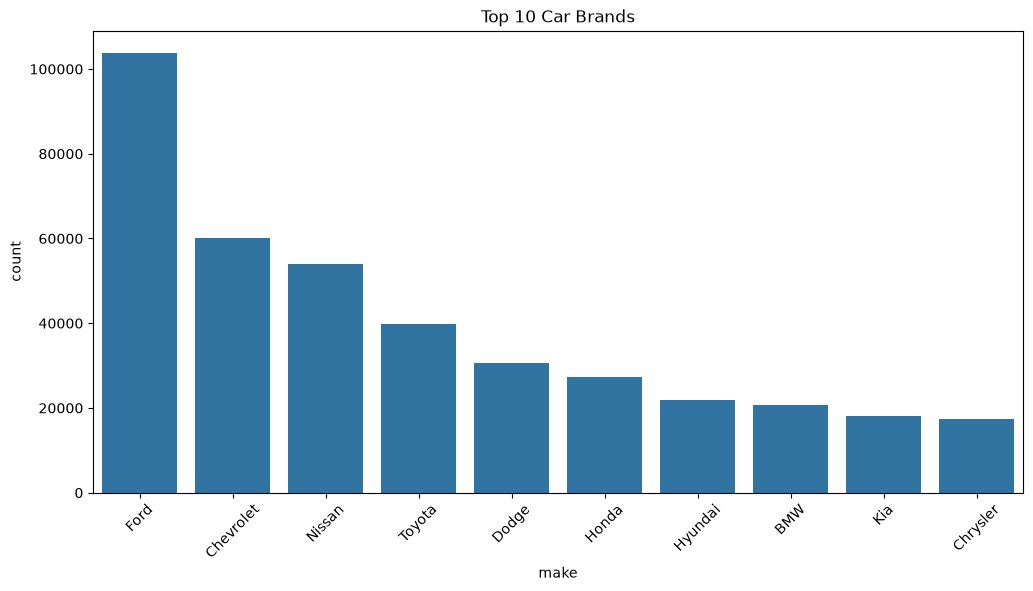

In [17]:
top10_make = df["make"].value_counts().head(10).index

plt.figure(figsize=(12,6))
sns.countplot(data=df, x="make", order=top10_make)
plt.xticks(rotation=45)
plt.title("Top 10 Car Brands")
plt.show()

#### Business Probleam

Which  care  brands  dominate  the  used  car  marked 

#### Business Solution 

Ford,   Chevrolet,   Nissan,   and    Toyota   have   the   highest  sales   volume
Dealers  should   prioritize  these   brands   for   better   sales   performance.


In [18]:
df.columns

Index(['year', 'make', 'model', 'trim', 'body', 'transmission', 'state',
       'condition', 'odometer', 'color', 'interior', 'seller', 'mmr',
       'sellingprice'],
      dtype='str')

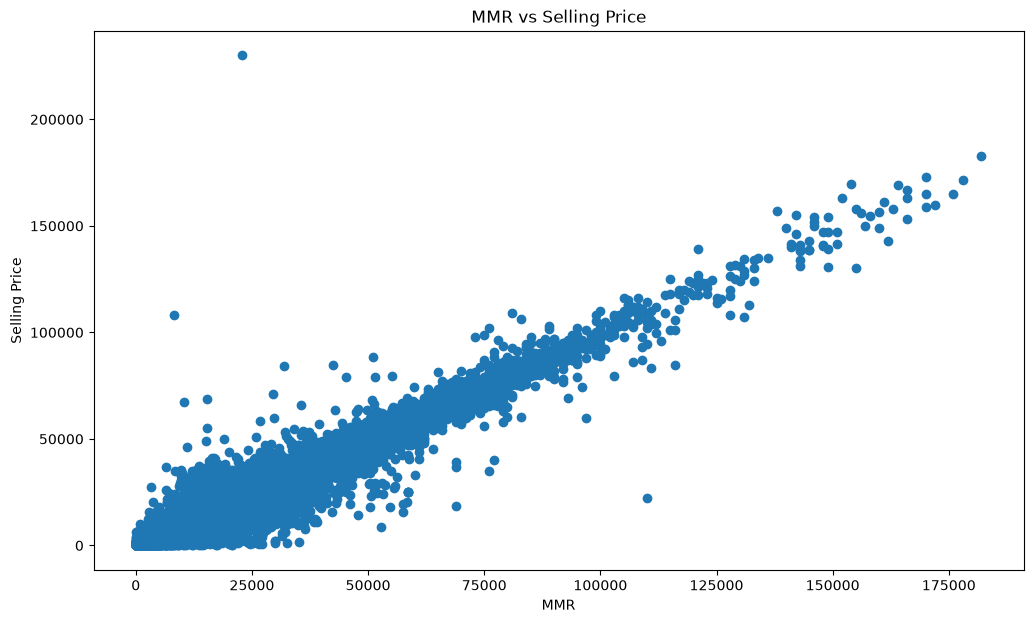

In [19]:
plt.figure(figsize=(12,7))
plt.scatter(df["mmr"], df["sellingprice"])
plt.title("MMR vs Selling Price")
plt.xlabel("MMR")
plt.ylabel("Selling Price")
plt.show()

### Business Problem

Does the MMR(Manheim market value)   accurately    predict   the   used   car  selling   pricle 

## Business Soluation

Cars   with   higher   MMR   values   generally   sell   at   higher   prices.
Dealers   can   use   MMR   to   set   competitive    selling   prices
Large   differences    between   MMR   and   selling   price   may   indicate   overpricing   or  underpricing 

## Key Insight

 Selling   pricle  has  a postivie  relationship with MMR


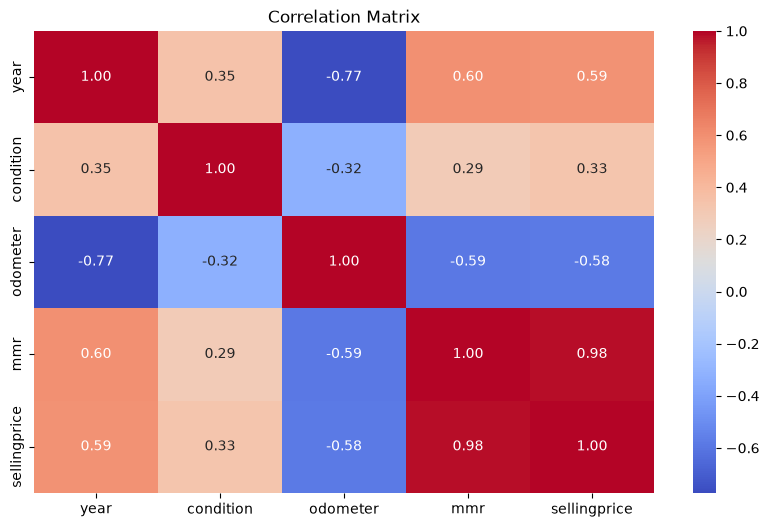

In [20]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

## Businees Problem
Which  varible  have  the  strong impact on  selling pricle

## Business Solution 

MMR   has the  strongest  positive   correlation   with   selling  price
Odometer   has   a   negative    correlation    with    selling   price
Dealers  should   use   MMR   and  mileage  while   estimating   vehicle  prices

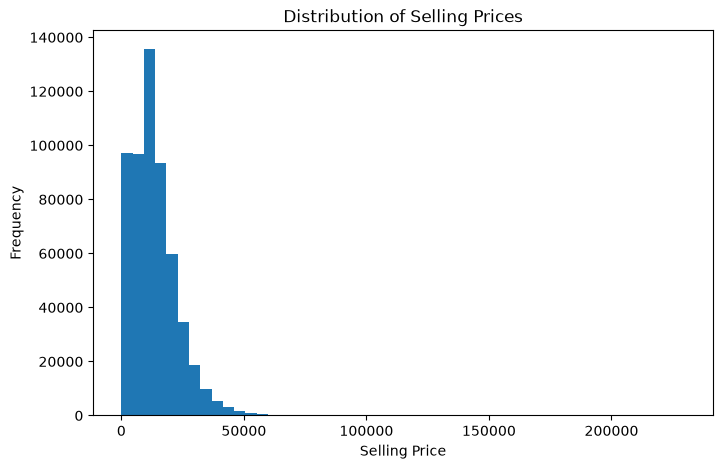

In [21]:
plt.figure(figsize=(8,5))
plt.hist(df["sellingprice"], bins=50)
plt.title("Distribution of Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Frequency")
plt.show()

## Bssines problem 

What  is  the  distribution  of  used  car  selling  prices
Are  most  cars  sold  in  the   low-price  or  high-price  range.

## Business Solution 

Most   cars   are   sold   in   the   lower   price   range
Premium-priced   vehicles   have   lower   demand
Dealers   should   keep   more   affordable   cars   to   maximize   sales   volume.


  



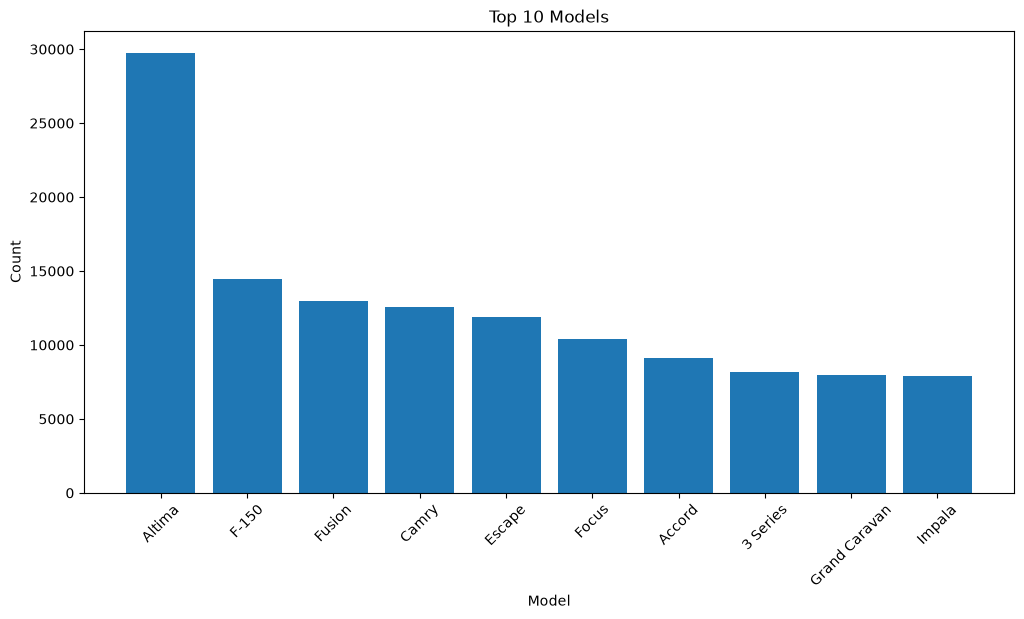

In [22]:
top10_model = df["model"].value_counts().head(10)

plt.figure(figsize=(12,6))
plt.bar(top10_model.index, top10_model.values)
plt.xticks(rotation=45)
plt.title("Top 10 Models")
plt.xlabel("Model")
plt.ylabel("Count")
plt.show()

## Business Problem

Which  car  modles  are   most  frequently  sold
which   moddles   should  dealears   keep   in  inventrory

## Business Solultion 

Most   cars   are    sold   in   the   lower   price    range
Premium  priced    vehicles   have    lower     demand

Dealers   should    keep   more   affordable   cars   to   maximize   sales   volume
Final   Project   Conclusion


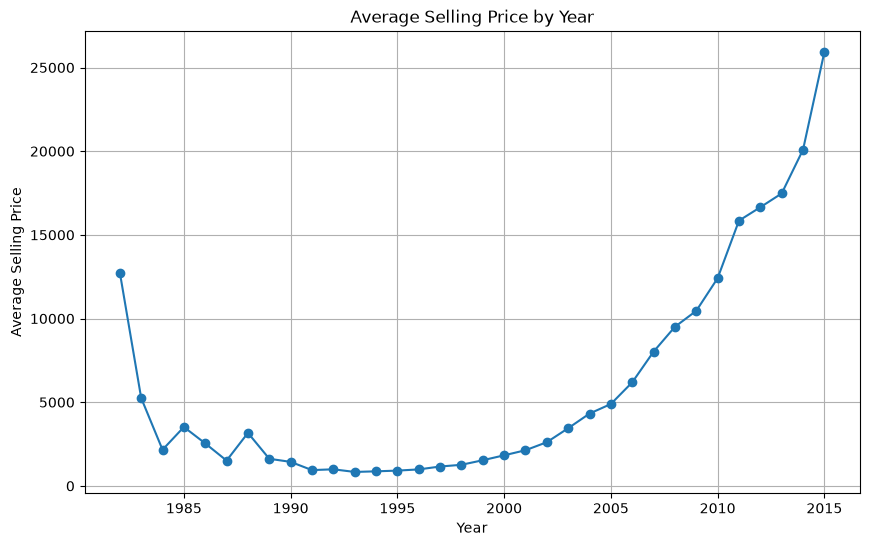

In [23]:
avg_price = df.groupby("year")["sellingprice"].mean()

plt.figure(figsize=(10,6))
plt.plot(avg_price.index, avg_price.values, marker="o")
plt.title("Average Selling Price by Year")
plt.xlabel("Year")
plt.ylabel("Average Selling Price")
plt.grid(True)
plt.show()

## Business  Problem 

How  has  the the  avearage  selling  pricle  of  cars changed  over  the  years ? 
Is   the  used  can    market   becoming  more  expensive  over  time ? 

## Business  Solution 

The   average  selling   price   has   increased   significantly   in  recent   years
Dealers   should   stock   more   recent   model   cars   because   they   generate   higher   revenue.



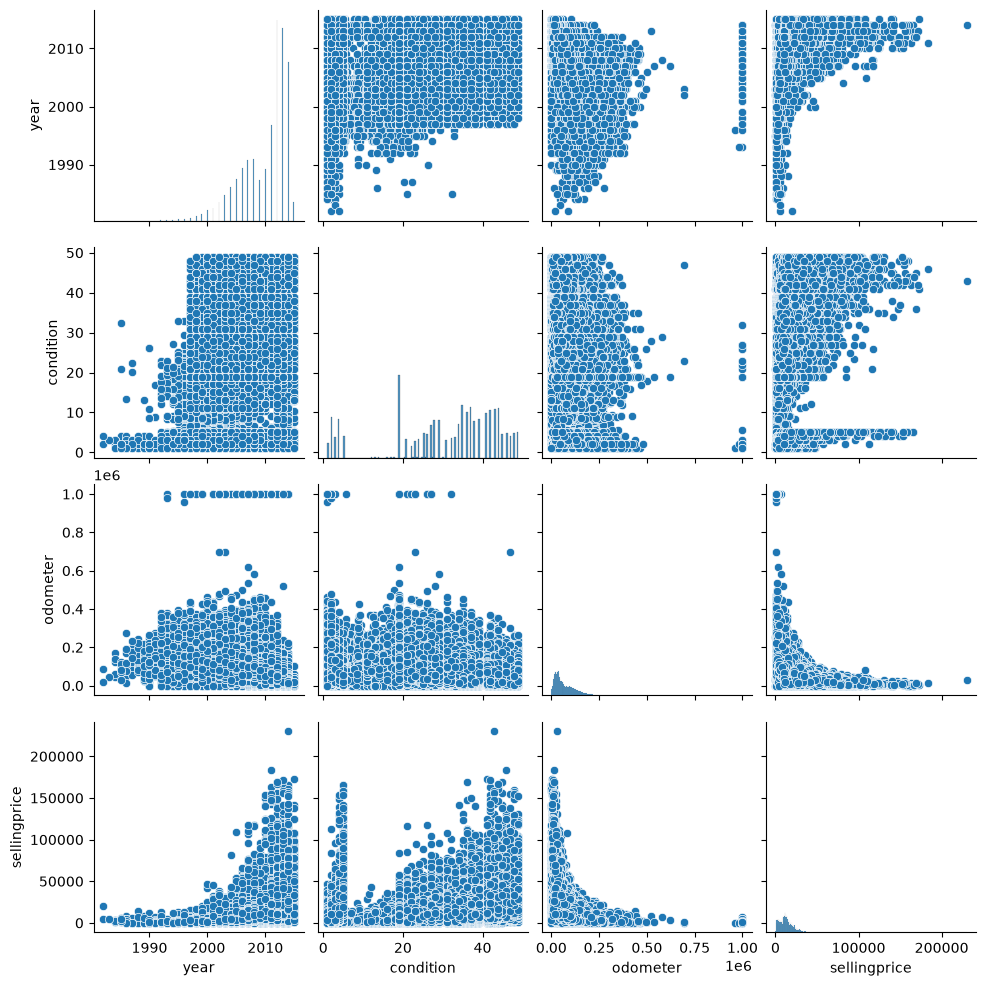

In [24]:
sample = df[["year","condition","odometer","sellingprice"]]
sns.pairplot(sample)
plt.show()


##  Business Problem

Which   variables   have   the   strongest   relationship   with   selling   price
Which   factors   influence   car   prices   the   most?

##  Business  Soulution 

Selling   price   is   positively   related   to   year   and   condition.
Selling   price   is   negatively   related   to   odometern   These  variables   should    be   considered   while   pricing    used    cars

### Final Project  Conclusion


## Business  Insights


Car   prices  have   increased   over   the   years
Lower   mileage   cars   sell   at   higher   prices
MMR   is   the   strongest   predictor   of    selling   price
Ford,   Chevrolet,   Nissan,   and   Toyota   dominate   the   market
Popular   models   such   as   Altima   and F-150   should   be   stocked  more  frequently
Most  customers   purchase   cars   in   the   affordable   price   range


Traget varble 

In [25]:
df.head()

,year,make,model,trim,body,transmission,state,condition,odometer,color,interior,seller,mmr,sellingprice
0,2015,Kia,Sorento,LX,SUV,automatic,ca,5.0,16639.0,white,black,kia motors america inc,20500.0,21500.0
1,2015,Kia,Sorento,LX,SUV,automatic,ca,5.0,9393.0,white,beige,kia motors america inc,20800.0,21500.0
2,2014,BMW,3 Series,328i SULEV,Sedan,automatic,ca,45.0,1331.0,gray,black,financial services remarketing (lease),31900.0,30000.0
3,2015,Volvo,S60,T5,Sedan,automatic,ca,41.0,14282.0,white,black,volvo na rep/world omni,27500.0,27750.0
4,2014,BMW,6 Series Gran Coupe,650i,Sedan,automatic,ca,43.0,2641.0,gray,black,financial services remarketing (lease),66000.0,67000.0


Numeric Conversion

In [26]:
x= df[["year", "condition", "odometer", "mmr"]]
y = df["sellingprice"]

In [27]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.20, random_state=42
)

In [28]:
x

,year,condition,odometer,mmr
0,2015,5.0,16639.0,20500.0
1,2015,5.0,9393.0,20800.0
2,2014,45.0,1331.0,31900.0
3,2015,41.0,14282.0,27500.0
4,2014,43.0,2641.0,66000.0
...,...,...,...,...
558832,2015,45.0,18255.0,35300.0
558833,2012,5.0,54393.0,30200.0
558834,2012,48.0,50561.0,29800.0
558835,2015,38.0,16658.0,15100.0


In [29]:
y

0         21500.0
1         21500.0
2         30000.0
3         27750.0
4         67000.0
           ...   
558832    33000.0
558833    30800.0
558834    34000.0
558835    11100.0
558836    26700.0
Name: sellingprice, Length: 558837, dtype: float64

In [30]:
from sklearn.linear_model import LinearRegression

In [31]:
model = LinearRegression()

In [32]:
model.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[-45.62, 38.51, -0. , 0.98]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['year','condition','odometer','mmr']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,9.065e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [33]:
y_pred = model.predict(x_test)

In [34]:
from sklearn.metrics import  r2_score

In [35]:
#Prediction 
y_pred = model.predict(x_test)
r2 = r2_score(y_test, y_pred)
accuracy = r2 * 100
print("R-squared:", r2)
print("Accuracy:", accuracy, "%")

R-squared: 0.9711063514140732
Accuracy: 97.11063514140731 %




Display the first 10 predicted values

In [36]:
print(y_pred[:10])

[12142.79636404  6322.98184827  7597.9859582  11173.28935607
 22323.06992791 12299.90300608  9434.34018528 12508.84784844
 22825.44428981  2367.91212883]


In [37]:
results = pd.DataFrame({
    "Actual Price": y_test.values[:10],
    "Predicted Price": y_pred[:10]
})

In [38]:
print(results)

   Actual Price  Predicted Price
0       13800.0     12142.796364
1        6300.0      6322.981848
2        8000.0      7597.985958
3       11400.0     11173.289356
4       23300.0     22323.069928
5       12700.0     12299.903006
6        9700.0      9434.340185
7       13100.0     12508.847848
8       18850.0     22825.444290
9        1000.0      2367.912129


In [39]:
from sklearn.tree import DecisionTreeRegressor

In [40]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV  ## help try the every parametre to so the which are best combintions


In [41]:
parameter = {
    'criterion': ['squared_error', 'absolute_error', 'poisson'],
    'splitter': ['best', 'random'],
    'max_depth': [1, 2, 3, 4],
    'max_features': [None, 'sqrt'],
    'ccp_alpha': [0.0, 0.01]
}

In [42]:
treemodel = DecisionTreeRegressor(random_state=42)

In [43]:
cv = GridSearchCV(
    treemodel,
    param_grid=parameter,
    cv=5,  ## cross validation mens divide the data 5 ports
    scoring='r2'  #choose the best model 
)

In [44]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
x, y, test_size=0.20,
 random_state=42
)

In [45]:
cv.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'ccp_alpha': [0.0, 0.01], 'criterion': ['squared_error', 'absolute_error', ...], 'max_depth': [1, 2, ...], 'max_features': [None, 'sqrt'], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callabl

In [46]:
cv.best_params_   # Best fit of the parametres

{'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': 4,
 'max_features': None,
 'splitter': 'best'}

In [47]:
print(cv.best_params_)

{'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': 4, 'max_features': None, 'splitter': 'best'}


In [48]:
print(cv.best_score_)

0.9539651996965809


In [49]:
y_pred = cv.predict(x_test)

In [50]:
print(y_pred)

[13744.13010029  5454.76438727  7572.08447205 ... 13744.13010029
 25826.32789003  9654.5450132 ]


In [51]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

print("R2 Score:", r2_score(y_test, y_pred))       #MODEL EXPLAINS
print("MAE:", mean_absolute_error(y_test, y_pred))  # CALCULATES  AVERAGE PREDICTION ERRO
print("MSE:", mean_squared_error(y_test, y_pred))  ## CALCULATES THE AVERAGE SUARED

R2 Score: 0.9560462709082784
MAE: 1326.707215379805
MSE: 4118479.686444434


In [52]:
from sklearn.linear_model import LogisticRegression

In [53]:
from sklearn.preprocessing import StandardScaler
StandardScaler

sklearn.preprocessing._data.StandardScaler

Feature Scaling

In [54]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

 Make a low to Low/High  to  target 

In [55]:

median_price = df["sellingprice"].median()

df["price_category"] = (df["sellingprice"] >= median_price).astype(int)

print(df["price_category"].value_counts())

price_category
1    281346
0    277491
Name: count, dtype: int64


train/test split (category)



In [56]:
from sklearn.model_selection import train_test_split

X = df[["year", "condition", "odometer", "mmr"]]
y = df["price_category"]

x_train, x_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print(x_train.shape)
print(x_test.shape)

(447069, 4)
(111768, 4)


Scaling


In [57]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print(x_train_scaled[:5])

[[ 0.24220818  0.40999679 -0.57706984  1.04466428]
 [ 0.24220818  0.26033016 -0.49405547  0.889929  ]
 [ 1.25034543  1.38282989 -1.14413214  4.33536783]
 [-0.76592907 -0.11383641  0.28791701 -0.96947324]
 [-0.76592907 -2.13433592  0.9304792  -0.59810858]]


Logistic Regression

In [58]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(x_train_scaled, y_train)

print("Model trained successfully")

Model trained successfully


Prediction

In [59]:
y_pred = logistic_model.predict(x_test_scaled)

print(y_pred[:10])

[0 0 0 0 1 1 0 1 1 0]


In [60]:
y

0         1
1         1
2         1
3         1
4         1
         ..
558832    1
558833    1
558834    1
558835    0
558836    1
Name: price_category, Length: 558837, dtype: int64

In [61]:
y_pred = model.predict(x_test)


In [62]:


print("Accuracy:", accuracy * 100, "%")

Accuracy: 9711.063514140731 %


In [63]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

print("R2 Score:", r2_score(y_test, y_pred))       #MODEL EXPLAINS
print("MAE:", mean_absolute_error(y_test, y_pred))  # CALCULATES  AVERAGE PREDICTION ERRO
print("MSE:", mean_squared_error(y_test, y_pred))  ## CALCULATES THE AVERAGE SUARED

R2 Score: -1104402806.1676784
MAE: 13600.082380552489
MSE: 276075585.9951258


In [64]:
from sklearn.metrics import confusion_matrix


In [65]:
from sklearn.ensemble import RandomForestRegressor

In [66]:
X = df[["year", "condition", "odometer", "mmr"]]
y = df["sellingprice"]

print(X.head())
print(y.head())
print(X.shape)
print(y.shape)

   year  condition  odometer      mmr
0  2015        5.0   16639.0  20500.0
1  2015        5.0    9393.0  20800.0
2  2014       45.0    1331.0  31900.0
3  2015       41.0   14282.0  27500.0
4  2014       43.0    2641.0  66000.0
0    21500.0
1    21500.0
2    30000.0
3    27750.0
4    67000.0
Name: sellingprice, dtype: float64
(558837, 4)
(558837,)


In [67]:
print(X.shape)
print(y.shape)

(558837, 4)
(558837,)


Train\Test Split

In [68]:
X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [69]:
print(X_train_rf.shape)
print(X_test_rf.shape)
print(y_train_rf.shape)
print(y_test_rf.shape)

(447069, 4)
(111768, 4)
(447069,)
(111768,)


Random Forest model

In [70]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created successfully")

Random Forest model created successfully


Model Training

In [71]:
rf_model.fit(X_train_rf, y_train_rf)

print("Random Forest Regressor trained successfully")

Random Forest Regressor trained successfully


Prediction 

In [72]:
y_pred_rf = rf_model.predict(X_test_rf)

print("First 10 predictions:")
print(y_pred_rf[:10])

First 10 predictions:
[13950.   7765.5  8336.  11642.  21345.  12748.   9393.  11684.5 22945.5
  2785. ]


Evaluation

In [73]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

r2_rf = r2_score(y_test_rf, y_pred_rf)
mae_rf = mean_absolute_error(y_test_rf, y_pred_rf)
mse_rf = mean_squared_error(y_test_rf, y_pred_rf)

print("Random Forest R2 Score:", r2_rf)
print("Random Forest R2 Percentage:", r2_rf * 100, "%")
print("Random Forest MAE:", mae_rf)
print("Random Forest MSE:", mse_rf)

Random Forest R2 Score: 0.9735690971230055
Random Forest R2 Percentage: 97.35690971230055 %
Random Forest MAE: 1010.8347863192805
Random Forest MSE: 2476584.782286193


In [74]:
results_rf = pd.DataFrame({
    "Actual Price": y_test_rf.values[:10],
    "Predicted Price": y_pred_rf[:10]
})

print(results_rf)

   Actual Price  Predicted Price
0       13800.0          13950.0
1        6300.0           7765.5
2        8000.0           8336.0
3       11400.0          11642.0
4       23300.0          21345.0
5       12700.0          12748.0
6        9700.0           9393.0
7       13100.0          11684.5
8       18850.0          22945.5
9        1000.0           2785.0


Model save

In [75]:
import joblib

joblib.dump(
    rf_model,
    "random_forest_car_price_model.pkl"
)

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [76]:
##from sklearn.svm import SVC

SVM MODEL

In [77]:
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    random_state=42
)

svm_model.fit(x_train_scaled, y_train)

print("SVM Model trained successfully")

NameError: name 'SVC' is not defined

Prediction

In [ ]:
y_pred_svm = svm_model.predict(x_test_scaled)

print("First 10 predictions:")
print(y_pred_svm[:5])

First 10 predictions:
[1 0 0 0 1 1 0 1 1 0]


Accuracy

In [ ]:
from sklearn.metrics import accuracy_score

accuracy_svm = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", accuracy_svm * 100, "%")

SVM Accuracy: 95.55418366616563 %


 Confusion Matrix

In [ ]:
from sklearn.metrics import confusion_matrix

cm_svm = confusion_matrix(y_test, y_pred_svm)

print("Confusion Matrix:")
print(cm_svm)

Confusion Matrix:
[[52823  2528]
 [ 2441 53976]]


 Classification Report

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

           0       0.96      0.95      0.96     55351
           1       0.96      0.96      0.96     56417

    accuracy                           0.96    111768
   macro avg       0.96      0.96      0.96    111768
weighted avg       0.96      0.96      0.96    111768

